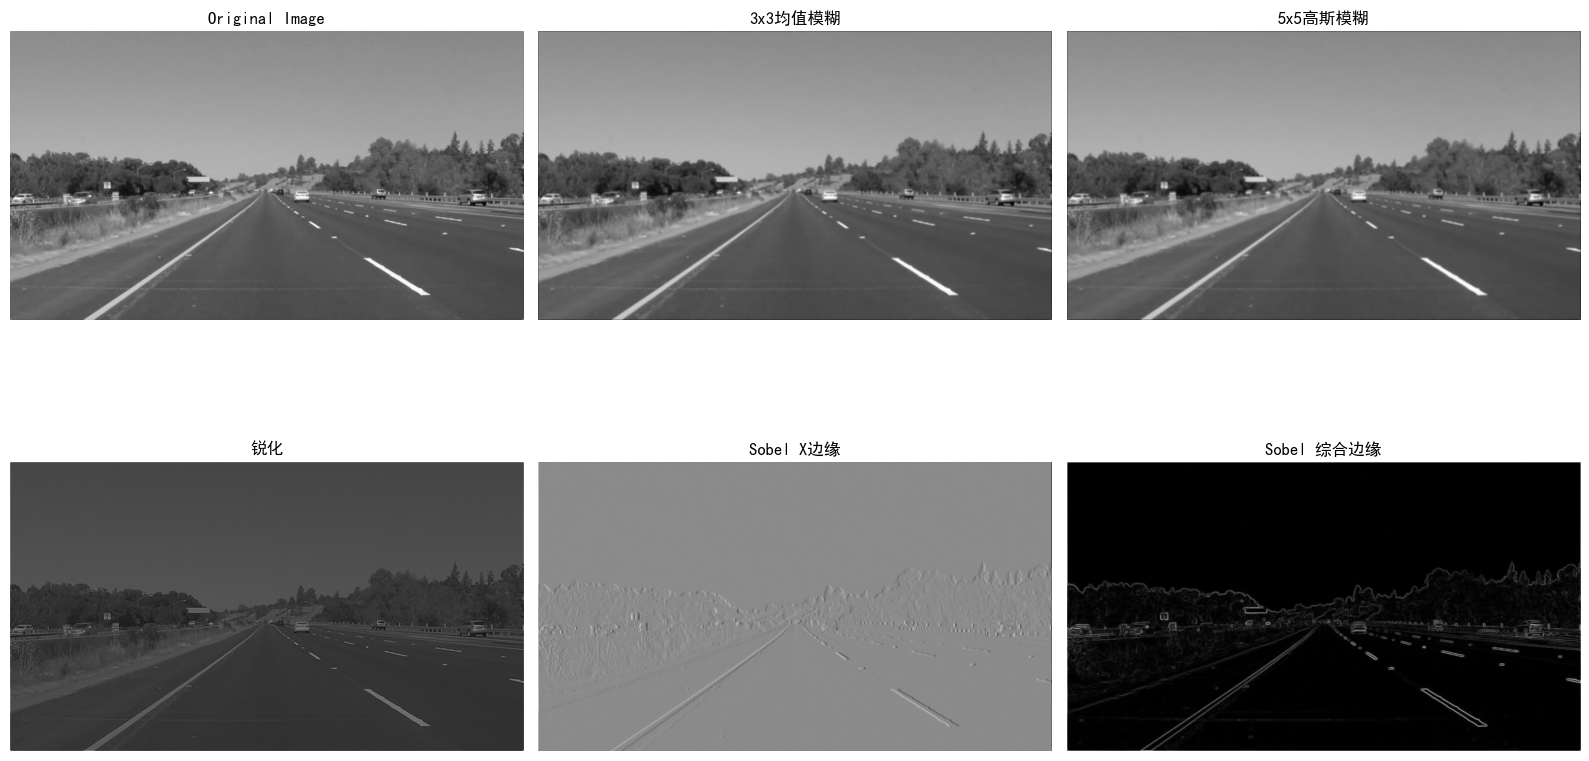

In [13]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False


img = Image.open('outer1.png').convert('L')  # Convert to grayscale
img_np = np.array(img,dtype=np.float32)

def conv2d(image,kernel,stride=1,padding="same"):
        img_h, img_w = image.shape
        k_h, k_w = kernel.shape

        if padding == "same":
                pad_h = (k_h - 1) // 2
                pad_w = (k_w - 1) // 2
        else:
                pad_h = 0
                pad_w = 0

        img_pad = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant')

        out_h = (img_h + 2 * pad_h - k_h) // stride + 1
        out_w = (img_w + 2 * pad_w - k_w) // stride + 1
        out = np.zeros((out_h, out_w), dtype=np.float32)


        for y in range(out_h):
            y_start = y * stride
            for x in range(out_w):
                x_start = x * stride
                window = img_pad[y_start:y_start + k_h, x_start:x_start + k_w]
                out[y, x] = np.sum(window * kernel)

        return out

blur_mean = np.ones((3,3)) / 9.0


def gaussian_kernel_5x5():
        g = np.array([
            [1,4,6,4,1],
            [4,16,24,16,4],
            [6,24,36,24,6],
            [4,16,24,16,4],
            [1,4,6,4,1]
    ])
        return g / np.sum(g)
blur_gauss =gaussian_kernel_5x5()


sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])


sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])


img_mean_blur = conv2d(img_np, blur_mean)
img_gauss_blur = conv2d(img_np, blur_gauss)
img_sharpen = conv2d(img_np, sharpen_kernel)
img_sobel_x = conv2d(img_np, sobel_x)
img_sobel_y = conv2d(img_np, sobel_y)

img_sobel = np.sqrt(img_sobel_x**2 + img_sobel_y**2)

plt.figure(figsize=(16, 10))
plt.subplot(2, 3, 1)
plt.imshow(img_np, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_mean_blur, cmap='gray')
plt.title('3x3均值模糊')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(img_gauss_blur, cmap='gray')
plt.title('5x5高斯模糊')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(img_sharpen, cmap='gray')
plt.title('锐化')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(img_sobel_x, cmap='gray')
plt.title('Sobel X边缘')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_sobel, cmap='gray')
plt.title('Sobel 综合边缘')
plt.axis('off')

plt.tight_layout()
plt.show()